# **Partie 1 : Exploration du dataset**

In [ ]:
import pandas as pd

# Charger le dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

# Afficher les premières lignes
print(df.head())

# Q1 : Combien de lignes et colonnes ?
print("Shape :", df.shape)

# Q2 : Quelles sont les variables ?
print("Colonnes :", df.columns)

# Q3 : Type de chaque variable
print(df.info())

# Q4 : Variable cible ?
# Churn

# Q5 : Valeurs manquantes ?
print("Valeurs manquantes:")
print(df.isnull().sum())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

# **Partie 2 : Nettoyage des données**

In [ ]:
# ================================
# Q1 : Colonnes avec valeurs manquantes ?
print("avant  remplacement :")
print(df.isnull().sum())
# ================================
df = df.replace(" ", pd.NA)

print("Après remplacement :")
print(df.isnull().sum())

# Nettoyage TotalCharges
#df['TotalCharges'] = df['TotalCharges'].replace(" ", pd.NA)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])

# Q2 : Supprimer ou imputer ?
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)
#df = df.dropna(subset=['TotalCharges'])

# Supprimer colonne inutile
df.drop('customerID', axis=1, inplace=True)

# Q3 : Pourquoi encoder ?

# Encodage LabelEncoder ou OneHotEncoding
df = pd.get_dummies(df, drop_first=True)

print("Dataset après nettoyage :")
print(df.head())

avant  remplacement :
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Après remplacement :
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0

/tmp/ipykernel_5985/1039114394.py:17: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


# **Partie 3 : Compréhension des données**

In [ ]:
# Statistiques descriptives
print(df.describe())

# Q1 : Moyenne MonthlyCharges
print("Moyenne MonthlyCharges :", df['MonthlyCharges'].mean())

# Q2 : Variable avec plus grande dispersion
print("Écart-type :")
print(df.std(numeric_only=True))

# Q3 : Variable cible équilibrée ?
print("Distribution churn :")
print(df['Churn_Yes'].value_counts(normalize=True))

       SeniorCitizen       tenure  MonthlyCharges  TotalCharges
count    7043.000000  7043.000000     7043.000000   7043.000000
mean        0.162147    32.371149       64.761692   2281.916928
std         0.368612    24.559481       30.090047   2265.270398
min         0.000000     0.000000       18.250000     18.800000
25%         0.000000     9.000000       35.500000    402.225000
50%         0.000000    29.000000       70.350000   1397.475000
75%         0.000000    55.000000       89.850000   3786.600000
max         1.000000    72.000000      118.750000   8684.800000
Moyenne MonthlyCharges : 64.76169246059918
Écart-type :
SeniorCitizen                               0.368612
tenure                                     24.559481
MonthlyCharges                             30.090047
TotalCharges                             2265.270398
gender_Male                                 0.500013
Partner_Yes                                 0.499748
Dependents_Yes                              0.4581

## **Partie 4 : Analyse descriptive**

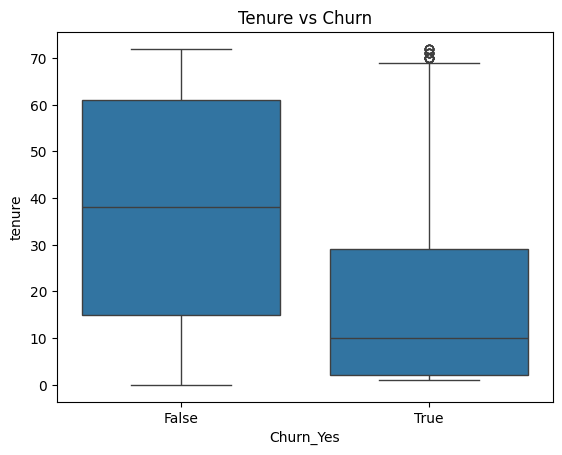

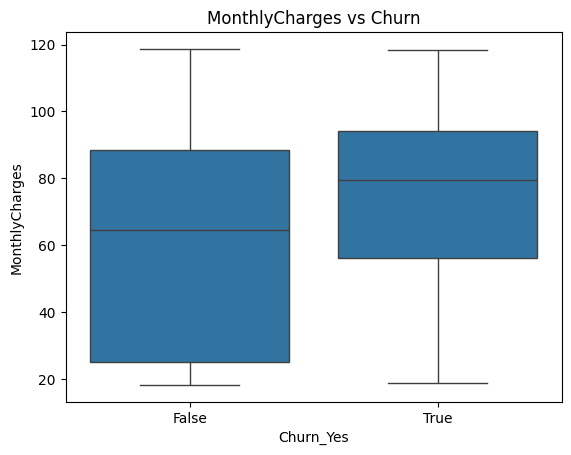

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Q1 : Relation tenure / churn
sns.boxplot(x='Churn_Yes', y='tenure', data=df)
plt.title("Tenure vs Churn")
plt.show()

# Q2 : MonthlyCharges vs churn
sns.boxplot(x='Churn_Yes', y='MonthlyCharges', data=df)
plt.title("MonthlyCharges vs Churn")
plt.show()

# ================================
# Q3 : Profils clients
# Réponse (analyse) :
# - Faible tenure → churn élevé
# - Charges élevées → churn
# - Contrat mensuel → risque élevé

# **Partie 5 : Modélisation Machine Learning**

In [ ]:
from sklearn.model_selection import train_test_split

# ================================
# Préparation données
X = df.drop('Churn_Yes', axis=1)
y = df['Churn_Yes']

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(max_iter=6000)
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)

In [ ]:
from sklearn.tree import DecisionTreeClassifier

model_tree = DecisionTreeClassifier()
model_tree.fit(X_train, y_train)

y_pred_tree = model_tree.predict(X_test)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model_knn = KNeighborsClassifier()
model_knn.fit(X_train, y_train)

y_pred_knn = model_knn.predict(X_test)

# **Partie 6 : Évaluation des modèles**

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# ================================
# Q1 : Accuracy des modèles
print("Logistic Regression Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Decision Tree Accuracy :", accuracy_score(y_test, y_pred_tree))
print("KNN Accuracy :", accuracy_score(y_test, y_pred_knn))

# ================================
# Q2 : Meilleure métrique ?
# Réponse : Recall (important pour détecter churners)

# ================================
# Q3 : Détection des churners
print("Rapport Logistic Regression")
print(classification_report(y_test, y_pred_lr))

print("Rapport Decision Tree")
print(classification_report(y_test, y_pred_tree))

print("Rapport KNN")
print(classification_report(y_test, y_pred_knn))

Logistic Regression Accuracy : 0.8218594748048261
Decision Tree Accuracy : 0.7097232079489
KNN Accuracy : 0.7771469127040455
Rapport Logistic Regression
              precision    recall  f1-score   support

       False       0.86      0.90      0.88      1036
        True       0.69      0.60      0.64       373

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409

Rapport Decision Tree
              precision    recall  f1-score   support

       False       0.80      0.80      0.80      1036
        True       0.45      0.46      0.45       373

    accuracy                           0.71      1409
   macro avg       0.63      0.63      0.63      1409
weighted avg       0.71      0.71      0.71      1409

Rapport KNN
              precision    recall  f1-score   support

       False       0.83      0.88      0.85      1036
        True       0.60      0.49      0.54       